In [5]:
import ctypes
import numpy as np
import matplotlib.pyplot as plt
import os
import numpy as np
from datetime import datetime
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok
from ctypes import c_int16, c_int32, byref, c_char_p

#chrome-extension://efaidnbmnnnibpcajpcglclefindmkaj/https://www.picotech.com/download/manuals/picoscope-6000-series-programmers-guide.pdf


def save_arrays(array1, array2, stage_position, laser_power, base_directory='D:/Data'):
    # Get current year, year+month, and year+month+day in the desired format
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')
    # Define the folder path following the structure Year/YearMonth/YearMonthDay
    folder_path = os.path.join(base_directory, year, year_month, year_month_day)
    # Create the directory structure if it doesn't exist
    os.makedirs(folder_path, exist_ok=True)
    # Create timestamp for file naming
    timestamp = datetime.now().strftime('%H%M%S')  # Using HHMMSS format for timestamp
    # File naming convention: pbec_timestamp_stageposition_laserpower.npy
    filename1 = f"pbec_{timestamp}_{stage_position}_{laser_power}_Voltage.txt"
    filename2 = f"pbec_{timestamp}_{stage_position}_{laser_power}_Time.txt"
    # Paths for the arrays to be saved
    array1_path = os.path.join(folder_path, f"{filename1}")
    array2_path = os.path.join(folder_path, f"{filename2}")
    # Save the arrays as .npy files
    np.savetxt(array1_path, array1,fmt='%0.4f')
    np.savetxt(array2_path, array2,fmt='%0.4f')


def get_picoscope_data(
    ch,
    analogue_offset=0,
    trig=0,
    trigsource=0,
    trigthresh=64,
    trigdir=2,
    trigdelay=0,
    trigms=1000,
    preTriggerSamples=2500,
    postTriggerSamples=2500,
    timebase=8,
    live_plot=False
):
    # Initialize PicoScope
    status = {}
    chandle = c_int16()
    serial = c_char_p()  # Leave serial empty for single device
    status["openunit"] = ps.ps6000OpenUnit(byref(chandle), serial)
    assert status["openunit"] == 0, f"Failed to open PicoScope 6407, error code: {status['openunit']}"

    # Channel configuration
    channel_mapping = {
        0: 'PS6000_CHANNEL_A',
        1: 'PS6000_CHANNEL_B',
        2: 'PS6000_CHANNEL_C',
        3: 'PS6000_CHANNEL_D'
    }
    
    if ch not in channel_mapping:
        raise ValueError("Invalid channel number. Must be 0, 1, 2, or 3.")
    
    channel = channel_mapping[ch]
    channel = ps.PS6000_CHANNEL[channel]
    enabled = 1 # 1 FOR ENABLING 0 FOR DISABLING
    coupling_type = ps.PS6000_COUPLING['PS6000_DC_50R']  # ONLY ONE TYPE OF COUPLING FOR 6407
    chARange = ps.PS6000_RANGE['PS6000_100MV']  # ONLY ONE TYPE OF Vrange FOR 6407 = ±100 mV range
    bandwidth = ps.PS6000_BANDWIDTH_LIMITER['PS6000_BW_FULL']  # Full bandwidth

    status["set_channel"] = ps.ps6000SetChannel(chandle, channel, enabled, coupling_type, chARange, analogue_offset, bandwidth)
    assert status["set_channel"] == 0, f"Error in setting channel: {status['set_channel']}"

    # TRIGGERING
    status["trigger"] = ps.ps6000SetSimpleTrigger(chandle, trig, trigsource, trigthresh, trigdir, trigdelay, trigms)
    assert_pico_ok(status["trigger"])

    # Set number of pre and post trigger samples to be collected
    maxSamples = preTriggerSamples + postTriggerSamples

    # Get timebase information
    timeIntervalns = ctypes.c_float()
    returnedMaxSamples = ctypes.c_int32()
    status["getTimebase2"] = ps.ps6000GetTimebase2(chandle, timebase, maxSamples, byref(timeIntervalns), 1, byref(returnedMaxSamples), 0)
    assert_pico_ok(status["getTimebase2"])

    # Run block capture
    status["runBlock"] = ps.ps6000RunBlock(chandle, preTriggerSamples, postTriggerSamples, timebase, 0, None, 0, None, None)
    assert_pico_ok(status["runBlock"])

    # Check for data collection to finish using ps6000IsReady
    ready = ctypes.c_int16(0)
    check = ctypes.c_int16(0)
    while ready.value == check.value:
        status["isReady"] = ps.ps6000IsReady(chandle, ctypes.byref(ready))

    # Create buffers for data collection
    bufferAMax = (ctypes.c_int16 * maxSamples)()
    bufferAMin = (ctypes.c_int16 * maxSamples)()  # Used for downsampling

    # Set data buffer location for data collection from the specified channel
    status["setDataBuffers"] = ps.ps6000SetDataBuffers(chandle, ch, byref(bufferAMax), byref(bufferAMin), maxSamples, 0)
    assert_pico_ok(status["setDataBuffers"])

    # Create overflow location
    overflow = ctypes.c_int16()
    cmaxSamples = ctypes.c_int32(maxSamples)

    # Retrieve data from scope to buffers assigned above
    status["getValues"] = ps.ps6000GetValues(chandle, 0, byref(cmaxSamples), 1, 0, 0, byref(overflow))
    assert_pico_ok(status["getValues"])

    # Find maximum ADC count value
    maxADC = ctypes.c_int16(32512)

    # Convert ADC counts data to mV
    adc2mVChAMax = adc2mV(bufferAMax, chARange, maxADC)

    # Create time data
    time = np.linspace(0, (cmaxSamples.value - 1) * timeIntervalns.value, cmaxSamples.value)

    # Plot data from channel if live_plot is enabled
    if live_plot:
        plt.plot(time, adc2mVChAMax[:])
        plt.xlabel('Time (ns)')
        plt.ylabel('Voltage (mV)')
        plt.title(f"PicoScope Data Capture on channel: {channel_mapping[ch]}")
        plt.grid()
        plt.show()
 
    # Stop the device
    status["stop"] = ps.ps6000Stop(chandle)
    assert_pico_ok(status["stop"])

    # Close unit (disconnect the scope)
    ps.ps6000CloseUnit(chandle)

    # Display status returns
    return adc2mVChAMax, time

In [21]:
%load_ext autoreload
%autoreload 2


import Components as comp
import socket
import sys

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

components = dict()

filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
laser = comp.Toptica_Laser()

THIS CODE IS FOR PICOSCOPE COHERENCE SCAN

In [22]:
%load_ext autoreload
%autoreload 2

import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

#_________________________________________________________CHANGE HERE____________________________________________________________
position_list = np.append(np.append(np.arange(0,90,5),np.arange(90,300,10)),np.arange(300,630,30))
# power_list = np.append(np.append(np.arange(56,70,0.5)/1000,np.arange(70,100,5)/1000),np.arange(100,150,10)/1000) #CHANGE HERE
#power_list = np.array([25.2])/1000
power_list = np.append(np.append(np.arange(35,70,1)/1000,np.arange(70,100,5)/1000),np.arange(100,150,10)/1000)

number_of_measurements = 1 # Amount of pics to take at each position of the stage
time_range = 1000
preSamples = 0
postSamples = 100000
plot_flag = False
#_________________________________________________________________________________________________________________________________

filter_positions = { # Preset the filter position for each power value - Need to be done manually, do it everytime before taking measurements
    43: 0,
    44: 1,
    50: 2,
    55: 3,
    65: 4,
    # Add more power settings as needed
}

with comp.Translation_Stage() as stage:
    for power in power_list:
        laser.set(power)
        print('Starting scan for power : ', power*1000)
        
        try:
            
            if power*1000 in filter_positions:
                    filter_position = filter_positions[power*1000]
                    filter_wheel.set(filter_position)  # Set the filter position accordingly
                    print(f'Filter position set to: {filter_position+1} for power {power*1000}')
                
            for k in range(len(position_list)):
                stage.set(position_list[k])
                position = stage.get_position()
                print('Now at Position : ', position)
                
                for k in range(number_of_measurements):
                    a = get_picoscope_data(0,live_plot=plot_flag,timebase = time_range, preTriggerSamples=preSamples,postTriggerSamples=postSamples)
                    Voltage = a[0]
                    Timing = a[1]
                    save_arrays(Voltage, Timing, position,power*1000)
                time.sleep(2)
        except:
            print('An exception occured')
        
    laser.set(0)
        

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\users\photonbec\appdata\local\programs\python\python38-32\lib\site-packages\pylablib\devices\Thorlabs\kinesis.py:206: UserWarning: model number BBD201 doesn't match the device ID prefix 73(BBD103)
  warnings.warn("model number {} doesn't match the device ID prefix {}({})".format(model_no,port,port_model_no))


Starting scan for power :  35.0
Now at Position :  0.0
Now at Position :  5.0
Now at Position :  10.0
Now at Position :  15.0
Now at Position :  20.0
Now at Position :  25.0
Now at Position :  30.00005
Now at Position :  35.0
Now at Position :  40.0
Now at Position :  44.9993
Now at Position :  49.99945
Now at Position :  55.00005
Now at Position :  59.9999
Now at Position :  65.00005
Now at Position :  69.99985
Now at Position :  74.99905
Now at Position :  79.9992
Now at Position :  85.0
Now at Position :  90.0
Now at Position :  100.0
Now at Position :  109.9996
Now at Position :  119.99975
Now at Position :  130.00005
Now at Position :  140.00005
Now at Position :  150.0
Now at Position :  160.0
Now at Position :  170.0001
Now at Position :  180.0
Now at Position :  190.0
Now at Position :  200.00005
Now at Position :  210.0
Now at Position :  220.0
Now at Position :  230.00005
Now at Position :  240.0
Now at Position :  250.0
Now at Position :  260.0
Now at Position :  270.0
Now a

THIS CODE IS FOR PICOSCOPE 1 MIRROR INTENSITY SCAN

In [ ]:
%load_ext autoreload
%autoreload 2

import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

#_________________________________________________________CHANGE HERE____________________________________________________________
position_list = np.arange(214,114,-10)
# power_list = np.append(np.append(np.arange(56,70,0.5)/1000,np.arange(70,100,5)/1000),np.arange(100,150,10)/1000) #CHANGE HERE
#power_list = np.array([25.2])/1000
power_list = np.append(np.append(np.arange(26,50,0.5)/1000,np.arange(50,70,1)/1000),np.arange(70,100,2)/1000)

number_of_measurements = 1 # Amount of pics to take at each position of the stage
time_range = 1000
preSamples = 0
postSamples = 100000
plot_flag = False
#_________________________________________________________________________________________________________________________________

filter_positions = { # Preset the filter position for each power value - Need to be done manually, do it everytime before taking measurements
    35: 0,
    40: 1,
    50: 2,
    60: 3,
    90: 4, 
    # Add more power settings as needed
}
position = 0

for power in power_list:
    laser.set(power)
    print('Starting scan for power : ', power*1000)
    
    try:
        
        if power*1000 in filter_positions:
                filter_position = filter_positions[power*1000]
                filter_wheel.set(filter_position)  # Set the filter position accordingly
                print(f'Filter position set to: {filter_position+1} for power {power*1000}')
            
        for k in range(number_of_measurements):
            a = get_picoscope_data(0,live_plot=plot_flag,timebase = time_range, preTriggerSamples=preSamples,postTriggerSamples=postSamples)
            Voltage = a[0]
            Timing = a[1]
            save_arrays(Voltage, Timing, position,power*1000)
        time.sleep(2)
    except:
        print('An exception occured')
    
laser.set(0)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Starting scan for power :  30.0
Starting scan for power :  30.5
Starting scan for power :  31.0


THIS IS FOR CHECKING THE RELEVANT FITLER POSITION

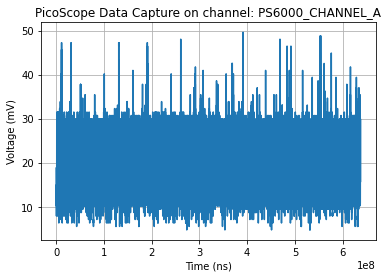

100000


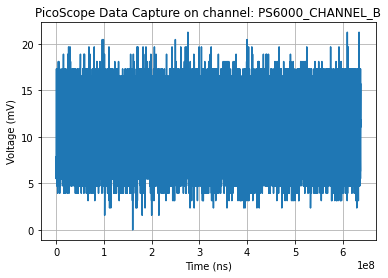

In [8]:
a = get_picoscope_data(0,live_plot=True,timebase = 1000, preTriggerSamples=0,postTriggerSamples=100000)
print(len(a[1]))
b = get_picoscope_data(1,live_plot=True,timebase = 1000, preTriggerSamples=0,postTriggerSamples=100000)

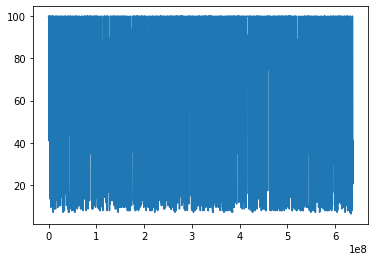

In [25]:
volt = np.load("D:/Data/2024/202410/20241030/pbec_142555_207.76395_50.0_Voltage.npy")
time = np.load("D:/Data/2024/202410/20241030/pbec_142555_207.76395_50.0_Time.npy")
plt.plot(time,volt)    